# SceneAligner — Structured3D Runner

Unified Colab runner delegating directly to [`runners/pipeline.py`](runners/pipeline.py), matching [`runners/run_vm.py`](runners/run_vm.py) with persistent GCS storage (`gs://scenealigner` default).

- **After Run 1**: `.env`, `Structured3D_annotation_3d.zip`, prepared `s3d_data/<profile>/scenes_*.tar` slices, `test_scenes_3250_3500.tar`, and lossless `float32` eval `--recon_cache` shards are persisted in GCS so subsequent runs require **zero external Structured3D downloads**.
- **Queueing cells**: After running `gcp-auth` (if needed), `clone-install`, and `env-setup`, you can queue `prepare-s3d`, `train-s3d`, and `eval-s3d`.
- **Development**: Push local edits with `./runners/sync.sh` before running `clone-install`.

In [ ]:
# Authenticate to GCP on consumer Colab (no-op on Colab Enterprise or when gcloud is already active)
import shutil
import subprocess

_active_gcp = ""
if shutil.which("gcloud"):
    _active_gcp = subprocess.run(
        [
            "gcloud",
            "auth",
            "list",
            "--filter=status:ACTIVE",
            "--format=value(account)",
        ],
        capture_output=True,
        text=True,
    ).stdout.strip()
if not _active_gcp:
    try:
        from google.colab import auth

        auth.authenticate_user()
    except ImportError:
        pass
    except:
        print("Maybe run: `gcloud auth login --no-launch-browser`")

In [3]:
import base64
import os
import subprocess
import sys

WORKSPACE = "/content/scenealigner_ws"
REPO_DIR = os.path.join(WORKSPACE, "Cs-5787-Project-Semantic-Localization")
REPO_URL = "https://github.com/lihengcao/Cs-5787-Project-Semantic-Localization.git"
BRANCH = "liheng"

os.makedirs(WORKSPACE, exist_ok=True)

GITHUB_TOKEN = os.environ.get("GITHUB_TOKEN", "").strip()
if not GITHUB_TOKEN:
    try:
        from google.colab import userdata

        GITHUB_TOKEN = (userdata.get("GITHUB_TOKEN") or "").strip()
    except Exception:
        GITHUB_TOKEN = ""

git_auth = []
if GITHUB_TOKEN:
    raw = f"x-access-token:{GITHUB_TOKEN}".encode("utf-8")
    b64 = base64.b64encode(raw).decode("ascii")
    git_auth = [
        "-c",
        f"http.https://github.com/.extraheader=Authorization: Basic {b64}",
    ]

if not os.path.exists(REPO_DIR):
    subprocess.run(["git", *git_auth, "clone", "-b", BRANCH, REPO_URL, REPO_DIR], check=True)
else:
    subprocess.run(["git", *git_auth, "-C", REPO_DIR, "fetch", "origin"], check=True)
    subprocess.run(
        ["git", "-C", REPO_DIR, "checkout", "-B", BRANCH, f"origin/{BRANCH}"],
        check=True,
    )

%cd {REPO_DIR}
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

!apt-get update -qq && apt-get install -y -qq p7zip-full aria2 libgl1

from runners import pipeline

pipeline.install_colab_deps()

/content/scenealigner_ws/Cs-5787-Project-Semantic-Localization
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libcares2:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libcares2_1.27.0-1.0ubuntu1.1_amd64.deb ...
Unpacking libcares2:amd64 (1.27.0-1.0ubuntu1.1) ...
Selecting previously unselected package libaria2-0:amd64.
Preparing to unpack .../libaria2-0_1.37.0+debian-1build3_amd64.deb ...
Unpacking libaria2-0:amd64 (1.37.0+debian-1build3) ...
Selecting previously unselected package aria2.
Preparing to unpack .../aria2_1.37.0+debian-1build3_amd64.deb ...
Unpacking aria2 (1.37.0+debian-1build3) ...
Setting up libcares2:amd64 (1.27.0-1.0ubuntu1.1) ...
Setting up libaria2-0:amd64 (1.37.0+debian-1build3) ...
Setting up aria2 (1.37.0+debian-1build3) ...
Pro

['shapely==2.1.2',
 'safetensors',
 'tqdm',
 'peft==0.18.1',
 'huggingface_hub',
 'viser==1.1.1',
 'transformers>=4.45,<6',
 'pi3 @ git+https://github.com/yyfz/Pi3.git@6acdeb033d337e90b9df7a77b0c8929231083f16',
 'geocalib @ git+https://github.com/cvg/GeoCalib.git@3ee7ec3411160fea5f3ac32377e53137e9119824',
 'dinov3 @ git+https://github.com/facebookresearch/dinov3.git@83318a8767dc346d5e11a70521860e0da2e1099b',
 'pytest']

In [4]:
!nvidia-smi
!df -h /content

import os
import sys

WORKSPACE = "/content/scenealigner_ws"
REPO_DIR = os.path.join(WORKSPACE, "Cs-5787-Project-Semantic-Localization")
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from runners import pipeline

# --- Run configuration ---
STAGES = ("prep", "train", "eval")
CHUNKS = [0, 1, 2]  # 0..14 (chunk 8 skipped automatically); ignored if ALL_TRAIN_CHUNKS=True
ALL_TRAIN_CHUNKS = False
SLICE_SCENES = 50

EPOCHS = 10
RESOLUTIONS = [512]
MIN_POINTS = 1000
SAVE_EVERY = 500
INIT_LORA = "jhcho99/SceneAligner/structured3d"
FREEZE_LORA = True
SEM_MODE = "consensus"
LAMBDA_SEM = 0.5
ALPHA_SEM = None
PHOTO_SEM_SOURCE = "gt"  # "gt" or "none"
INCLUDE_ROOMS = False
STRUCTURAL_PHOTO_SEMANTICS = False
USE_RECON_CACHE = True
EVAL_MODES = None
EVAL_CHECKPOINT_DIR = None

GCS_BACKUP_URI = None  # None -> .env or gs://scenealigner
NO_GCS = False
S3D_BASE_URL = None  # None -> .env / GCS config/.env (or interactive prompt only when external download needed)
RUN_ID = None  # None -> YYYY-MM-DD_HH-MM-SSZ_<slug> (auto-resumes matching incomplete ACTIVE_RUN)
NEW_RUN = False
TAG = None
KEEP_ZIPS = False
KEEP_RAW_VIEWS = False

SESSION = pipeline.init_session(
    workspace=WORKSPACE,
    stages=STAGES,
    chunks=CHUNKS,
    all_train_chunks=ALL_TRAIN_CHUNKS,
    slice_scenes=SLICE_SCENES,
    epochs=EPOCHS,
    resolutions=RESOLUTIONS,
    min_points=MIN_POINTS,
    save_every=SAVE_EVERY,
    init_lora=INIT_LORA,
    freeze_lora=FREEZE_LORA,
    sem_mode=SEM_MODE,
    lambda_sem=LAMBDA_SEM,
    alpha_sem=ALPHA_SEM,
    photo_sem_source=PHOTO_SEM_SOURCE,
    include_rooms=INCLUDE_ROOMS,
    structural_photo_semantics=STRUCTURAL_PHOTO_SEMANTICS,
    use_recon_cache=USE_RECON_CACHE,
    eval_modes=EVAL_MODES,
    eval_checkpoint_dir=EVAL_CHECKPOINT_DIR,
    gcs_uri=GCS_BACKUP_URI,
    no_gcs=NO_GCS,
    s3d_base_url=S3D_BASE_URL,
    run_id=RUN_ID,
    new_run=NEW_RUN,
    tag=TAG,
    keep_zips=KEEP_ZIPS,
    keep_raw_views=KEEP_RAW_VIEWS,
)

Mon Nov 16 20:45:01 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   37C    P8             16W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

[2026-11-16 20:46:08 UTC] === Stage: smoke ===
....................................................................                                             [100%]
=================================================== warnings summary ===================================================
../../../usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491
  /usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
    warnings.warn(

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html
68 passed, 1 warning in 39.55s
Installing dependencies...
Hit:1 https://cli.github.com/packages stable InRelease
Hit:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease                            
Hit:3 http://security.ubuntu.com/ubuntu noble-security InRelease                                                       
Hit:4 http://archive.ub

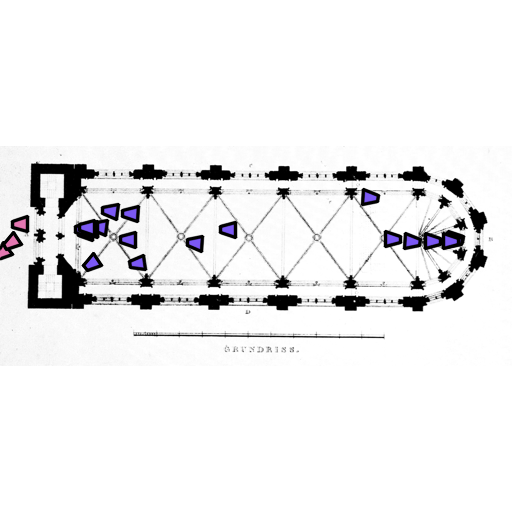

In [5]:
# Optional smoke test: pytest + demo render
SESSION.run_smoke()

from IPython.display import Image, display

display(Image(f"{SESSION.paths['workspace']}/demo_S221/cameras.png", width=450))

In [6]:
# Prepare Structured3D training slices (restores & heals GCS slices when available)
SESSION.run_prep()

[2026-11-16 20:49:47 UTC] === Stage: prep (profile=photo-gt, chunks=[0, 1, 2], slice_scenes=50) ===
[2026-11-16 20:49:52 UTC] Restoring photo-gt/scenes_0_200.tar from GCS...
[2026-11-16 20:50:34 UTC] Restoring photo-gt/scenes_200_400.tar from GCS...
[2026-11-16 20:51:22 UTC] Restoring photo-gt/scenes_400_450.tar from GCS...
[2026-11-16 20:51:38 UTC] Restoring photo-gt/scenes_450_500.tar from GCS...
[2026-11-16 20:51:54 UTC] Restoring photo-gt/scenes_500_550.tar from GCS...
[2026-11-16 20:52:12 UTC] Restoring photo-gt/scenes_550_600.tar from GCS...
[2026-11-16 20:52:30 UTC] Chunk 0 (0..200) already prepared; skipping.
[2026-11-16 20:52:30 UTC] Chunk 1 (200..400) already prepared; skipping.
[2026-11-16 20:52:30 UTC] Chunk 2 (400..600) already prepared; skipping.


In [7]:
# Train Semantic Adapter / LoRA (strictly honors CHUNKS via --scene_ranges, auto-resumes & syncs checkpoints to GCS)
SESSION.run_train()

[2026-11-16 20:52:31 UTC] === Stage: train (run=2026-11-15_21-59-04Z_s3d_photo-gt_consensus_c0-2_ep10, profile=photo-gt, chunks=[0, 1, 2], epochs=10) ===
[2026-11-16 20:52:34 UTC] --- Training chunk through epoch 9/10 ---
Reconstructing (incomplete total...): |                                                    |  0.00B /  0.00B            

Fetching 2 files:   0%|                                                                           | 0/2 [00:00<?, ?it/s]

Fetching 2 files:  50%|█████████████████████████████████▌                                 | 1/2 [00:00<00:00,  2.33it/s]

Fetching 2 files: 100%|███████████████████████████████████████████████████████████████████| 2/2 [00:02<00:00,  1.27s/it]
Download complete: █████████████████████████████████████████████████████████████████████████████████| 9.02MB, 9.82MB/s  
Reconstruction complete: 100%|█████████████████████████████████████████████████████████████| 9.55MB / 9.55MB, 4.08MB/s  
Download complete: ██████████████████████████████

In [8]:
# Evaluate on Structured3D test scenes (03250..03499) using GCS-backed test scenes & float32 recon cache, then record run summary
SESSION.run_eval()
SESSION.write_final_results()

[2026-11-16 22:56:45 UTC] === Stage: eval (checkpoint=/content/scenealigner_ws/runs/2026-11-15_21-59-04Z_s3d_photo-gt_consensus_c0-2_ep10, modes=['none', 'uniform', 'consensus'], photo_sem=gt) ===
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
Warning, cannot find cuda-compiled version of RoPE2D, using a slow pytorch version instead
Loading weights: 100%|█████████████████████████████████████████████████████████████| 197/197 [00:00<00:00, 13041.21it/s]
[transformers] CLIPTextModelWithProjection LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXP

{'run_id': '2026-11-15_21-59-04Z_s3d_photo-gt_consensus_c0-2_ep10',
 'run_name': '2026-11-15_21-59-04Z_s3d_photo-gt_consensus_c0-2_ep10',
 'resumed': True,
 'photo_sem_source': 'gt',
 'floorplan_sem_source': 's3d_annos',
 'prep_profile': 'photo-gt',
 'started_at_utc': '2026-11-15T21:59:04Z',
 'finished_at_utc': '2026-11-17T01:07:01Z',
 'git_commit': '1d78423',
 'stages': ['prep', 'train', 'eval'],
 'workspace': '/content/scenealigner_ws',
 'run_dir': '/content/scenealigner_ws/runs/2026-11-15_21-59-04Z_s3d_photo-gt_consensus_c0-2_ep10',
 'prepared_scene_ranges': [[0, 200],
  [200, 400],
  [400, 450],
  [450, 500],
  [500, 550],
  [550, 600]],
 'config': {'chunks': [0, 1, 2],
  'slice_scenes': 50,
  'epochs': 10,
  'resolutions': [512],
  'min_points': 1000,
  'save_every': 500,
  'init_lora': 'jhcho99/SceneAligner/structured3d',
  'freeze_lora': True,
  'sem_mode': 'consensus',
  'lambda_sem': 0.5,
  'alpha_sem': None,
  'photo_sem_source': 'gt',
  'include_rooms': False,
  'structural_

In [9]:
# Manual/full backup of prepared slices, test scenes, eval recon cache, and run outputs to GCS
SESSION.run_backup()

[2026-11-17 01:07:33 UTC] === Stage: backup ===


In [10]:
# Auto disconnect from colab after saving backups
try:
    from google.colab import runtime

    runtime.unassign()
except Exception:
    pass